In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
import statsmodels.api as sm
from scipy import stats 
from statsmodels.stats.outliers_influence import variance_inflation_factor 
from statsmodels.stats.stattools import durbin_watson 
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score , mean_squared_error

In [3]:
df = pd.read_csv(r"/Users/satwik/Downloads/Student_Performance.csv")
print("Data loaded successfully!!!")

Data loaded successfully!!!


In [6]:
print(df.head())
print(df.info())
print(df.describe())
print("Missing values\n",df.isnull().sum())

   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------              

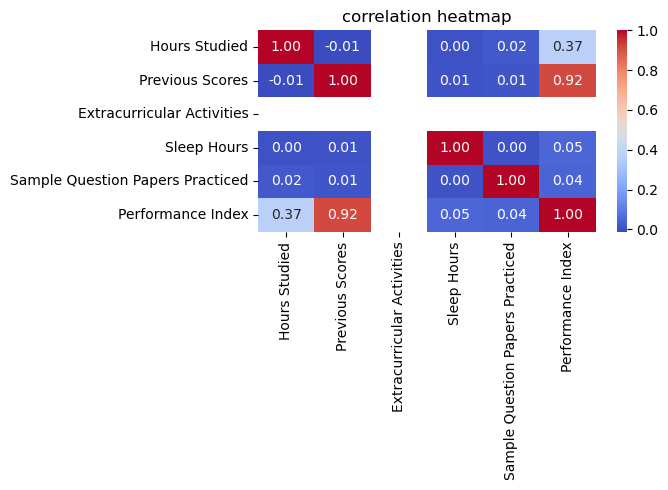

In [8]:
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes" : 1 , "No" : 0})
plt.figure(figsize=(7,5))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("correlation heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()


==Simple Linear Regression==
Intercept (b0): 41.436634826537336
Slope (b1): 2.784300441170454
R2: 0.13160425385996855
RMSE: 17.939190012852034


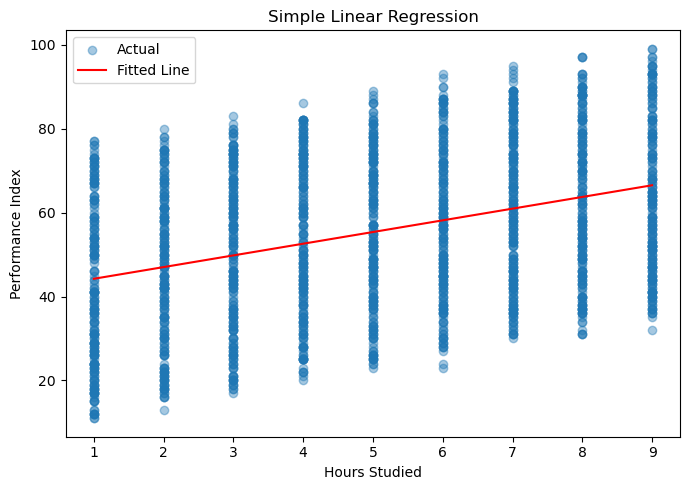

In [11]:
x_simple = df[["Hours Studied"]]
y = df["Performance Index"]

xs_train, xs_test, ys_train, ys_test = train_test_split(
    x_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(xs_train, ys_train)

print("\n==Simple Linear Regression==")
print("Intercept (b0):", simple_model.intercept_)
print("Slope (b1):", simple_model.coef_[0])

ys_pred = simple_model.predict(xs_test)

print("R2:", r2_score(ys_test, ys_pred))
print("RMSE:", np.sqrt(mean_squared_error(ys_test, ys_pred)))

plt.figure(figsize=(7, 5))
plt.scatter(xs_test, ys_test, alpha=0.4, label="Actual")

sorted_x = xs_test.sort_values("Hours Studied")

plt.plot(
    sorted_x,
    simple_model.predict(sorted_x),
    color="red",
    label="Fitted Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple Linear Regression")
plt.tight_layout()
plt.savefig("02_simple_fit.png")
plt.show()

In [18]:
from sklearn.impute import SimpleImputer

# Remove rows where target value is missing
df = df.dropna(subset=["Performance Index"])

x = df.drop(columns="Performance Index")
y = df["Performance Index"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# Handle missing values
imputer = SimpleImputer(strategy="median")

x_train = imputer.fit_transform(x_train)
x_test = imputer.transform(x_test)

# Multiple Linear Regression
multi_model = LinearRegression()
multi_model.fit(x_train, y_train)

print("\n===Multiple Linear Regression===")
print("Intercept:", multi_model.intercept_)

for name, coef in zip(x.columns, multi_model.coef_):
    print(f"{name:35s} {coef:.4f}")

y_pred = multi_model.predict(x_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

n, p = x_test.shape
adj_r2 = 1 - (1-r2) * (n-1) / (n-p-1)

print("R2:", r2)
print("Adjusted R2:", adj_r2)
print("RMSE:", rmse)


===Multiple Linear Regression===
Intercept: -33.602067327491305
Hours Studied                       2.8529
Previous Scores                     1.0170
Extracurricular Activities          0.4733
Sleep Hours                         0.1917
R2: 0.9887144552384186
Adjusted R2: 0.9886918275797487
RMSE: 2.0450562130645262


/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['Extracurricular Activities']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['Extracurricular Activities']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.988
Model:                            OLS   Adj. R-squared:                  0.988
Method:                 Least Squares   F-statistic:                 1.709e+05
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:10:17   Log-Likelihood:                -17151.
No. Observations:                8000   AIC:                         3.431e+04
Df Residuals:                    7995   BIC:                         3.435e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -33.6021      0.142   -235.944      0

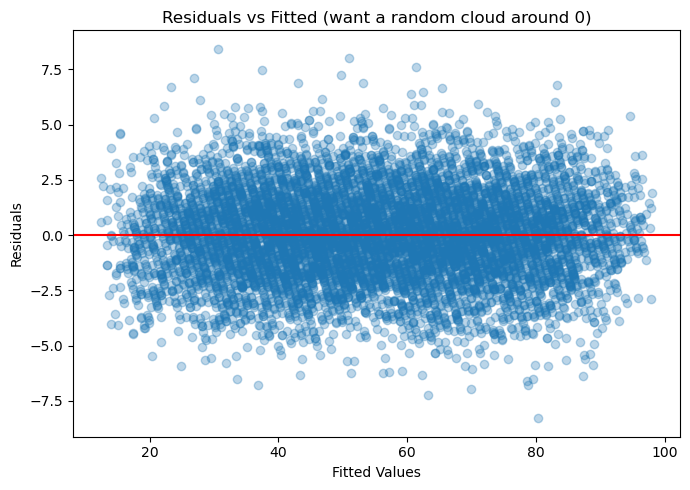

In [21]:
x_train_sm=sm.add_constant(x_train)
ols=sm.OLS(y_train,x_train_sm).fit()
print("\n",ols.summary())
fitted = ols.fittedvalues
resid=ols.resid
plt.figure(figsize=(7,5))
plt.scatter(fitted,resid,alpha=0.3)
plt.axhline(0,color="red")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (want a random cloud around 0)")
plt.tight_layout()
plt.savefig("03_resid_vs_fitted.png")
plt.show()           

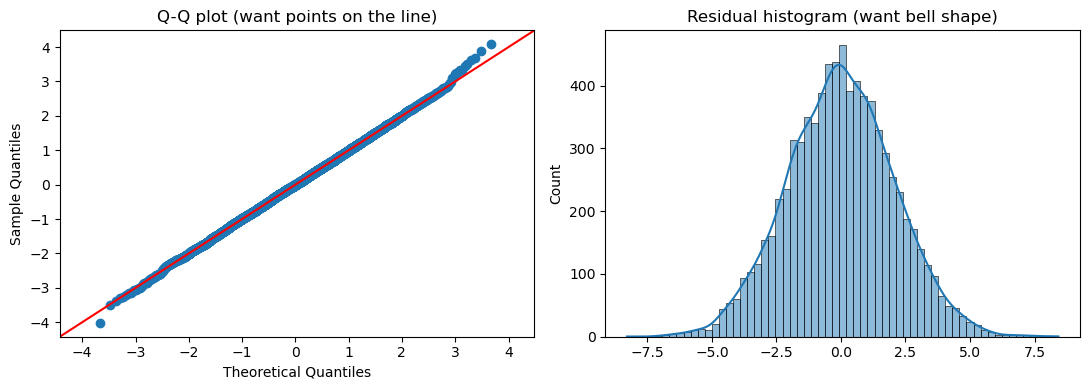

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sm.qqplot(resid, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")

sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")

plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

In [30]:
import numpy as np
import pandas as pd

bp_stat, bp_p, _, _ = het_breuschpagan(resid, x_train_sm)

print("Breusch-Pagan p value:", bp_p)
print("Durbin-Watson:", durbin_watson(resid))

# Convert numpy array into DataFrame
vif_data = pd.DataFrame(x_train_sm)

# Assign feature names
if np.allclose(vif_data.iloc[:, 0], 1):
    vif_data.columns = ["const"] + [
        f"x{i}" for i in range(1, vif_data.shape[1])
    ]
else:
    vif_data.columns = [
        f"x{i}" for i in range(vif_data.shape[1])
    ]

vif = pd.DataFrame({
    "feature": vif_data.columns,
    "VIF": [
        variance_inflation_factor(vif_data.values, i)
        for i in range(vif_data.shape[1])
    ]
})

print("\nVIF:\n", vif[vif["feature"] != "const"])

Breusch-Pagan p value: 0.20887452618939129
Durbin-Watson: 2.0440059887388955

VIF:
   feature       VIF
1      x1  1.000375
2      x2  1.000236
3      x3  1.000052
4      x4  1.000319


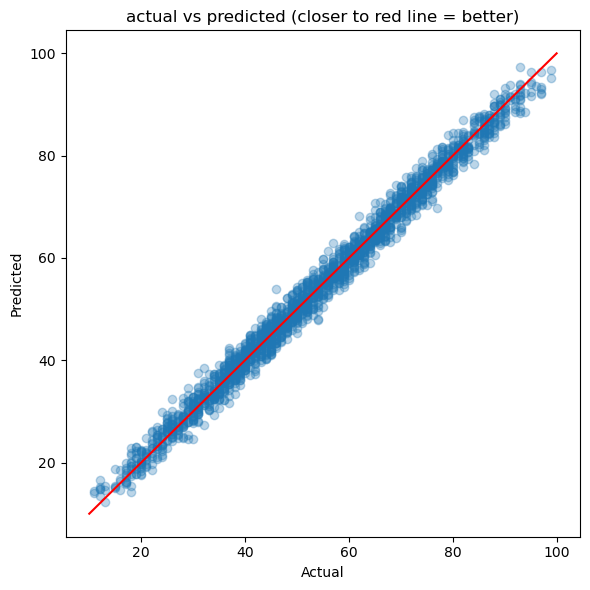

In [33]:
plt.figure(figsize=(6,6))
plt.scatter(y_test , y_pred , alpha=0.3)
plt.plot([y.min() , y.max()] , [y.min() , y.max()] , color = "red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("actual vs predicted (closer to red line = better)")
plt.tight_layout()
plt.savefig("0.5_actual_vs_pred.png")
plt.show()